In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

/home/vansh-talyani/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1793482174.149513   19357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793482174.189977   19357 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793482175.307649   19357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
train = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_test.csv")

In [3]:
x_train = train.drop(['label'],axis=1).values
y_train = train['label'].values

In [4]:
x_test = test.drop(['label'],axis=1).values
y_test = test['label'].values

In [5]:
x_train = x_train.astype('float32')/255
x_test = x_test.astype('float32')/255

In [6]:
image_shape = (28,28,1)
num_classes=10

In [7]:
x_train = x_train.reshape(-1,*image_shape)
x_test = x_test.reshape(-1,*image_shape)

In [8]:
model = Sequential()
model.add(Conv2D(32,(3,3),activation='relu',input_shape=image_shape))
model.add(MaxPooling2D((2,2)))

/home/vansh-talyani/.local/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1793482181.088112   19357 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793482181.107178   19357 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [9]:
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

In [10]:
model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(num_classes,activation='softmax'))

In [11]:
model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
hr = model.fit(x_train,y_train,batch_size=128,validation_split=0.2,epochs=11)


Epoch 1/11


W0000 00:00:1793482184.608432   19357 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8932 - loss: 0.3555 - val_accuracy: 0.9743 - val_loss: 0.0869
Epoch 2/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9688 - loss: 0.1014 - val_accuracy: 0.9844 - val_loss: 0.0576
Epoch 3/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9776 - loss: 0.0721 - val_accuracy: 0.9834 - val_loss: 0.0540
Epoch 4/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9820 - loss: 0.0594 - val_accuracy: 0.9873 - val_loss: 0.0449
Epoch 5/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9850 - loss: 0.0488 - val_accuracy: 0.9885 - val_loss: 0.0402
Epoch 6/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9872 - loss: 0.0411 - val_accuracy: 0.9887 - val_loss: 0.0410
Epoch 7/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9880 - loss: 0.0367 - val_accuracy: 0.9875 - val_loss: 0.0462
Epoch 8/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9899 - loss: 0.0330 - val_accuracy: 0.98

In [17]:
test_loss,test_acc = model.evaluate(x_test,y_test)
print(test_acc*100)
print(test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9913 - loss: 0.0319
99.12999868392944
0.03185588866472244


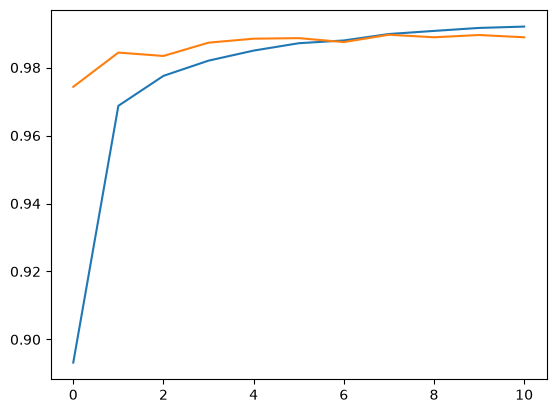

In [18]:
plt.plot(hr.history['accuracy'],label='accuracy')
plt.plot(hr.history['val_accuracy'],label='val_accuracy')
plt.legend
plt.show()

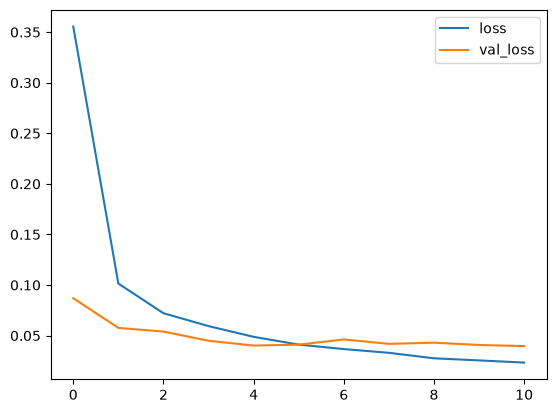

In [19]:
plt.plot(hr.history['loss'], label='loss')
plt.plot(hr.history['val_loss'], label='val_loss')
plt.legend()
plt.show()